In [9]:
import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import lru_cache
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score
from joblib import Parallel, delayed

FILES = {
    "ethereum": "ethereum-historical-data.csv",
    "solana":   "solana-historical-data (4).csv",
    "tether":   "tether-historical-data (2).csv",
}
ASSET = "ethereum"
PEER  = "solana"
HORIZON       = 20
N_FOLDS_TUNE  = 4
N_FOLDS_FINAL = 15
N_JOBS        = -1

In [10]:
def to_number(col):
    return pd.to_numeric(col.astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")

@lru_cache(maxsize=None)
def load_daily(asset):
    df = pd.read_csv(FILES[asset], encoding="utf-8-sig")
    df = df.set_index(pd.to_datetime(df["Дата"])).sort_index()
    d = pd.DataFrame({
        "Close":  to_number(df["Закрыть"]),
        "Volume": to_number(df["Объём"]),
        "Cap":    to_number(df["Капитализ."]),
    })
    full = pd.date_range(d.index.min(), d.index.max(), freq="D")
    d = d.reindex(full).interpolate(method="time")
    d.index.freq = "D"
    return d

@lru_cache(maxsize=None)
def make_exog_cached(asset, peer):
    own = load_daily(asset)
    lv = np.log(own["Volume"].replace(0, np.nan))
    ex = pd.DataFrame({"vol_z": lv - lv.rolling(30).mean()}, index=own.index)
    if peer and peer in FILES:
        ex["peer_r"] = np.log(load_daily(peer)["Close"]).diff().shift(1)
    if "tether" in FILES:
        ex["usdt_chg"] = np.log(load_daily("tether")["Cap"]).diff()
    return ex

In [11]:
def build_design(train, exog):
    logp = np.log(train.to_numpy())
    r    = pd.Series(np.diff(logp, prepend=np.nan))
    lp   = pd.Series(logp)
    F = pd.DataFrame({
        "ret_3":  r.rolling(3).sum(),  "ret_7":  r.rolling(7).sum(),
        "ret_14": r.rolling(14).sum(), "ret_30": r.rolling(30).sum(),
        "vol_7":  r.rolling(7).std(),  "vol_30": r.rolling(30).std(),
        "dist_ma30_z": (lp - lp.rolling(30).mean()) / lp.rolling(30).std(),
    })
    for lag in range(1, 11):
        F[f"r_{lag}"] = r.shift(lag - 1)
    F["vol_ratio"] = F.vol_7 / F.vol_30

    if exog is not None and not exog.empty:
        E = exog.loc[train.index].reset_index(drop=True)
        F = pd.concat([F, E, E.rolling(7).mean().add_suffix("_7")], axis=1)

    lp_arr = lp.to_numpy()
    Y = np.full((len(logp), HORIZON), np.nan)
    for k in range(1, HORIZON + 1):
        Y[:-k, k - 1] = lp_arr[k:] - lp_arr[:-k]
    return F, Y, logp[-1]

def fit_one_step(F, y, params):
    m = HistGradientBoostingRegressor(
        random_state=0,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        **params,
    )
    m.fit(F, y)
    return m

def fit_direct_fast(train, exog, params):
    F, Y, last_logp = build_design(train, exog)
    x_now = F.iloc[[-1]].to_numpy()
    valid_F = F.notna().all(axis=1).to_numpy()

    idxs = [np.where(valid_F & ~np.isnan(Y[:, k]))[0] for k in range(HORIZON)]
    models = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(fit_one_step)(F.iloc[idx], Y[idx, k], params)
        for k, idx in enumerate(idxs)
    )
    preds = np.array([m.predict(x_now)[0] for m in models])
    return np.exp(last_logp + preds)

def walk_forward(s, params, n_folds):
    ex_full = make_exog_cached(ASSET, PEER)
    rows = []
    for k in range(n_folds):
        cut = len(s) - (n_folds - k) * HORIZON
        if cut <= 60:
            continue
        train, test = s.iloc[:cut], s.iloc[cut:cut + HORIZON]
        pred = fit_direct_fast(train, ex_full.loc[train.index], params)
        rows.append({"fold": k + 1, "test_start": test.index[0].date(),
                     "y_true": test.values, "y_pred": pred})
    return rows

In [12]:
def r2_vs_naive(y_true, y_pred):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    naive = np.repeat(y_true[0], len(y_true))
    ss_res   = np.sum((y_true - y_pred) ** 2)
    ss_naive = np.sum((y_true - naive) ** 2)
    return np.nan if ss_naive == 0 else 1 - ss_res / ss_naive

def aggregate_metrics(rows):
    y_true = np.concatenate([r["y_true"] for r in rows])
    y_pred = np.concatenate([r["y_pred"] for r in rows])
    err = y_true - y_pred

    mape = np.mean(np.abs(err / y_true)) * 100
    rmse = np.sqrt(np.mean(err ** 2))
    mae  = np.mean(np.abs(err))
    r2_c = r2_score(y_true, y_pred)
    r2_n = r2_vs_naive(y_true, y_pred)

    lt = np.concatenate([np.diff(np.log(r["y_true"])) for r in rows])
    lp = np.concatenate([np.diff(np.log(r["y_pred"])) for r in rows])
    r2_l = r2_score(lt, lp)
    dir_acc = np.mean(np.sign(lt) == np.sign(lp)) * 100
    corr = float(np.corrcoef(lt, lp)[0, 1]) if lt.std() > 0 and lp.std() > 0 else np.nan
    rmse_ret = float(np.sqrt(np.mean((lt - lp) ** 2))) * 100

    return {
        "MAPE_%":        mape,
        "RMSE":          rmse,
        "MAE":           mae,
        "R2_classic":    r2_c,
        "R2_vs_naive":   r2_n,
        "R2_logret":     r2_l,
        "Direction_%":   dir_acc,
        "Corr_logret":   corr,
        "RMSE_ret_%":    rmse_ret,
    }

def plot_folds(rows, title):
    all_true = np.concatenate([r["y_true"] for r in rows])
    all_pred = np.concatenate([r["y_pred"] for r in rows])
    x = np.arange(len(all_true))

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(14, 7), sharex=True,
        gridspec_kw={"height_ratios": [3, 1]},
    )
    ax1.plot(x, all_true, color="#111827", lw=2, label="Реальность")
    ax1.plot(x, all_pred, color="#E8590C", lw=1.6, ls="--", label="Прогноз")
    pos = 0
    for r in rows:
        ax1.axvline(pos, color="#ADB5BD", ls=":", lw=0.8)
        pos += len(r["y_true"])
    ax1.set_ylabel("Цена, $"); ax1.set_title(title)
    ax1.legend(loc="best"); ax1.grid(alpha=0.25)

    err_pct = (all_pred - all_true) / all_true * 100
    ax2.bar(x, err_pct, color=np.where(err_pct >= 0, "#2F9E44", "#C92A2A"), width=1.0)
    ax2.axhline(0, color="#111827", lw=0.8)
    ax2.axhline( 10, color="#868E96", ls="--", lw=1)
    ax2.axhline(-10, color="#868E96", ls="--", lw=1)
    ax2.set_ylabel("Ошибка, %"); ax2.set_xlabel("День теста")
    ax2.grid(alpha=0.25)
    plt.tight_layout(); plt.show()

ethereum: 1097 дней 2022-06-09 -> 2025-06-09
[1/6] MAPE=11.30%  R2_naive=+0.197  R2_logret=-0.369  Dir=46.1%  (17s)
[2/6] MAPE=11.35%  R2_naive=+0.175  R2_logret=-0.366  Dir=50.0%  (29s)
[3/6] MAPE=11.11%  R2_naive=+0.304  R2_logret=-0.271  Dir=52.6%  (43s)
[4/6] MAPE=11.16%  R2_naive=+0.283  R2_logret=-0.325  Dir=55.3%  (54s)
[5/6] MAPE=11.05%  R2_naive=+0.231  R2_logret=-0.331  Dir=55.3%  (71s)
[6/6] MAPE=10.80%  R2_naive=+0.293  R2_logret=-0.303  Dir=50.0%  (87s)

Подбор закончен за 87s. Финальный прогон на 15 фолдах...
Финальный прогон: 62s

Параметры: {'max_iter': 500, 'learning_rate': 0.02, 'max_depth': 2, 'min_samples_leaf': 30, 'l2_regularization': 0.5}

Метрики по 15 фолдам (300 дней теста):
  MAPE_%         =     9.328
  RMSE           =   348.867
  MAE            =   248.174
  R2_classic     =     0.663
  R2_vs_naive    =     0.663
  R2_logret      =    -0.371
  Direction_%    =    52.281
  Corr_logret    =    -0.101
  RMSE_ret_%     =     4.499

Фолды:
  fold  1  start=2024

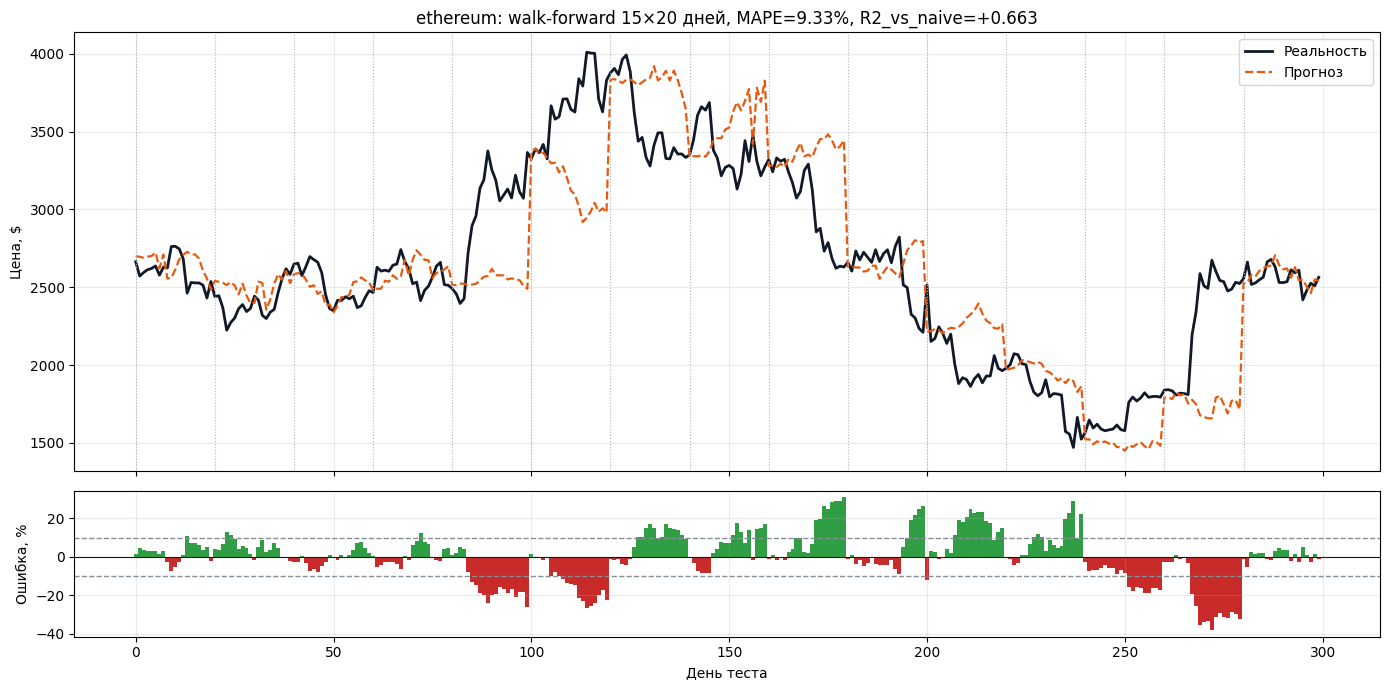

In [13]:
GRID = [
    {"max_iter": 300, "learning_rate": 0.03, "max_depth": 3, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"max_iter": 300, "learning_rate": 0.05, "max_depth": 3, "min_samples_leaf": 20, "l2_regularization": 1.0},
    {"max_iter": 400, "learning_rate": 0.03, "max_depth": 2, "min_samples_leaf": 10, "l2_regularization": 0.5},
    {"max_iter": 400, "learning_rate": 0.05, "max_depth": 2, "min_samples_leaf": 10, "l2_regularization": 0.5},
    {"max_iter": 500, "learning_rate": 0.02, "max_depth": 3, "min_samples_leaf": 30, "l2_regularization": 1.0},
    {"max_iter": 500, "learning_rate": 0.02, "max_depth": 2, "min_samples_leaf": 30, "l2_regularization": 0.5},
]

def main():
    s = load_daily(ASSET)["Close"].dropna()
    print(f"{ASSET}: {len(s)} дней {s.index.min().date()} -> {s.index.max().date()}")

    t0 = time.time()
    best = (np.inf, None)
    for i, params in enumerate(GRID, 1):
        rows = walk_forward(s, params, n_folds=N_FOLDS_TUNE)
        m = aggregate_metrics(rows)
        print(f"[{i}/{len(GRID)}] MAPE={m['MAPE_%']:5.2f}%  "
              f"R2_naive={m['R2_vs_naive']:+.3f}  R2_logret={m['R2_logret']:+.3f}  "
              f"Dir={m['Direction_%']:.1f}%  ({time.time()-t0:.0f}s)")
        if m["MAPE_%"] < best[0]:
            best = (m["MAPE_%"], params)

    _, params = best
    print(f"\nПодбор закончен за {time.time()-t0:.0f}s. Финальный прогон на {N_FOLDS_FINAL} фолдах...")

    t1 = time.time()
    rows = walk_forward(s, params, n_folds=N_FOLDS_FINAL)
    m = aggregate_metrics(rows)
    print(f"Финальный прогон: {time.time()-t1:.0f}s")

    print("\nПараметры:", params)
    print(f"\nМетрики по {N_FOLDS_FINAL} фолдам ({N_FOLDS_FINAL*HORIZON} дней теста):")
    for k, v in m.items():
        print(f"  {k:14s} = {v:9.3f}")

    print("\nФолды:")
    for r in rows:
        print(f"  fold {r['fold']:2d}  start={r['test_start']}")

    plot_folds(rows, f"{ASSET}: walk-forward {N_FOLDS_FINAL}×{HORIZON} дней, "
                     f"MAPE={m['MAPE_%']:.2f}%, R2_vs_naive={m['R2_vs_naive']:+.3f}")

if __name__ == "__main__":
    main()